# Week 4: Neural Network for Clickbait Headline Detection
**Course:** TECH 405 – Artificial Neural Network & Deep Learning

Dataset chosen in Week 2: *Clickbait Headline Dataset* (32,000 headlines, label 1 = clickbait, 0 = non-clickbait).

**Plan**
1. Reload the data and repeat the Week 2 stratified 70/15/15 split (same seed).
2. Convert headlines to integer sequences (fixed length taken from the Week 2 length analysis).
3. Build a feed-forward neural network (Embedding → pooling → Dense layers → sigmoid) in Keras.
4. Adjust hyperparameters one at a time (learning rate, hidden units, dropout, batch size, optimizer, embedding size) and observe validation results.
5. Select the best configuration using the **validation** set, then evaluate **once** on the test set with a confusion matrix, precision, recall, and F-score.

In [1]:
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

# ---- Configuration ----
DATA_PATH  = "clickbait_data.csv"   # change if your file is elsewhere (e.g. "/content/clickbait_data.csv")
MAX_TOKENS = 20000                  # vocabulary size cap
MAX_LEN    = 25                     # Week 2: median 9 words, max 26 -> 25 keeps almost every headline intact
EPOCHS     = 15                     # upper limit; EarlyStopping usually stops sooner
OUT_DIR    = "outputs"; os.makedirs(OUT_DIR, exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


## 1. Load data and split

In [3]:
df = pd.read_csv(DATA_PATH)
print(df.shape); print(df["clickbait"].value_counts())

X, y = df["headline"].astype(str), df["clickbait"]
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)
print("Train / Val / Test:", len(X_train), len(X_val), len(X_test))

(32000, 2)
clickbait
0    16001
1    15999
Name: count, dtype: int64
Train / Val / Test: 22400 4800 4800


In [4]:
vectorizer = layers.TextVectorization(max_tokens=MAX_TOKENS, output_mode="int", output_sequence_length=MAX_LEN)
vectorizer.adapt(X_train.values)

def vec(s): return vectorizer(tf.constant(s.values)).numpy()
Xtr, Xva, Xte = vec(X_train), vec(X_val), vec(X_test)
print("Vocabulary size:", vectorizer.vocabulary_size())
print("Example:", X_train.iloc[0]); print(Xtr[0])

Vocabulary size: 20000
Example: 39 Things You'll Only Understand If You Went To College In The Early 2000s
[1605   24  139  117  137   54    6  396    2  350    3    4  769 2480
    0    0    0    0    0    0    0    0    0    0    0]


In [12]:
def build_model(emb_dim=32, hidden_units=64, dropout=0.3, lr=1e-3, optimizer="adam"):
    model = keras.Sequential([
        layers.Input(shape=(MAX_LEN,), dtype="int32"),
        layers.Embedding(MAX_TOKENS, emb_dim),
        layers.GlobalAveragePooling1D(),
        layers.Dense(hidden_units, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ])
    opts = {"adam": keras.optimizers.Adam, "sgd": keras.optimizers.SGD, "rmsprop": keras.optimizers.RMSprop}
    model.compile(optimizer=opts[optimizer](learning_rate=lr), loss="binary_crossentropy", metrics=["accuracy"])
    return model

def run_experiment(name, batch_size=64, **kw):
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(**kw)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(Xtr, y_train.values, validation_data=(Xva, y_val.values),
                     epochs=EPOCHS, batch_size=batch_size, callbacks=[es], verbose=0)
    prob = model.predict(Xva, verbose=0).ravel(); pred = (prob >= 0.5).astype(int)
    res = dict(experiment=name, batch_size=batch_size, **kw,
               epochs_run=len(hist.history["loss"]),
               train_acc=hist.history["accuracy"][-1],
               val_acc=accuracy_score(y_val, pred),
               val_precision=precision_score(y_val, pred), val_recall=recall_score(y_val, pred),
               val_f1=f1_score(y_val, pred), val_loss=min(hist.history["val_loss"]),
               seconds=round(time.time()-t0, 1))
    print(f"{name:28s} val_acc={res['val_acc']:.4f} val_f1={res['val_f1']:.4f} epochs={res['epochs_run']}")
    return res, model, hist

## 2. Text vectorization

baseline                     val_acc=0.9708 val_f1=0.9703 epochs=11


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 25, 32)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,926,533 (7.35 MB)

 Trainable params: 642,177 (2.45 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,284,356 (4.90 MB)

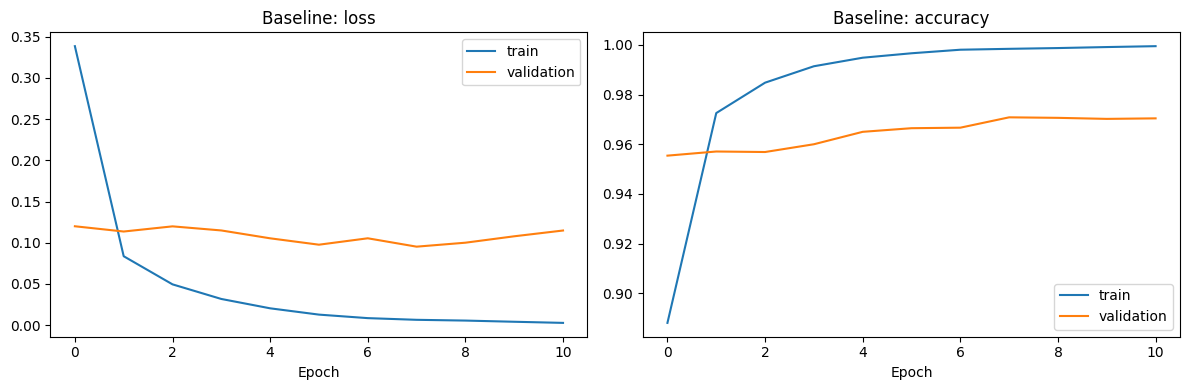

In [6]:
BASE = dict(emb_dim=32, hidden_units=64, dropout=0.3, lr=1e-3, optimizer="adam")
base_res, base_model, base_hist = run_experiment("baseline", batch_size=64, **BASE)
base_model.summary()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(base_hist.history["loss"], label="train"); ax[0].plot(base_hist.history["val_loss"], label="validation")
ax[0].set_title("Baseline: loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(base_hist.history["accuracy"], label="train"); ax[1].plot(base_hist.history["val_accuracy"], label="validation")
ax[1].set_title("Baseline: accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/baseline_curves.png", dpi=150); plt.show()

In [7]:
grid = {
    "lr":           [0.01, 0.001, 0.0001],
    "hidden_units": [16, 64, 128],
    "dropout":      [0.0, 0.3, 0.5],
    "emb_dim":      [16, 32, 64],
    "optimizer":    ["adam", "sgd", "rmsprop"],
    "batch_size":   [32, 64, 256],
}
results, models = [base_res], {"baseline": base_model}
seen = {"baseline"}
for param, values in grid.items():
    for v in values:
        name = f"{param}={v}"
        if v == (BASE.get(param) if param != "batch_size" else 64):   # identical to baseline
            continue
        cfg = dict(BASE); bs = 64
        if param == "batch_size": bs = v
        else: cfg[param] = v
        r, m, _ = run_experiment(name, batch_size=bs, **cfg)
        results.append(r); models[name] = m

res_df = pd.DataFrame(results).sort_values("val_f1", ascending=False).reset_index(drop=True)
res_df.to_csv(f"{OUT_DIR}/hyperparameter_results.csv", index=False)
res_df[["experiment","val_acc","val_precision","val_recall","val_f1","val_loss","epochs_run","seconds"]].round(4)

lr=0.01                      val_acc=0.9742 val_f1=0.9740 epochs=5
lr=0.0001                    val_acc=0.9652 val_f1=0.9646 epochs=15
hidden_units=16              val_acc=0.9669 val_f1=0.9660 epochs=10
hidden_units=128             val_acc=0.9590 val_f1=0.9576 epochs=5
dropout=0.0                  val_acc=0.9688 val_f1=0.9681 epochs=9
dropout=0.5                  val_acc=0.9592 val_f1=0.9578 epochs=5
emb_dim=16                   val_acc=0.9704 val_f1=0.9699 epochs=11
emb_dim=64                   val_acc=0.9579 val_f1=0.9568 epochs=4
optimizer=sgd                val_acc=0.5173 val_f1=0.0917 epochs=15
optimizer=rmsprop            val_acc=0.9696 val_f1=0.9694 epochs=15
batch_size=32                val_acc=0.9696 val_f1=0.9691 epochs=5
batch_size=256               val_acc=0.9738 val_f1=0.9735 epochs=15


,experiment,val_acc,val_precision,val_recall,val_f1,val_loss,epochs_run,seconds
0,lr=0.01,0.9742,0.9810,0.9671,0.9740,0.0804,5,26.7
1,batch_size=256,0.9738,0.9814,0.9658,0.9735,0.0748,15,18.0
2,baseline,0.9708,0.9875,0.9538,0.9703,0.0953,11,47.6
3,emb_dim=16,0.9704,0.9875,0.9529,0.9699,0.0903,11,23.8
4,optimizer=rmsprop,0.9696,0.9767,0.9621,0.9694,0.0965,15,38.4
5,batch_size=32,0.9696,0.9858,0.9529,0.9691,0.0823,5,26.8
6,dropout=0.0,0.9688,0.9891,0.9479,0.9681,0.0949,9,26.6
7,hidden_units=16,0.9669,0.9912,0.9421,0.9660,0.0978,10,29.0
8,lr=0.0001,0.9652,0.9815,0.9483,0.9646,0.0911,15,40.5
9,dropout=0.5,0.9592,0.9902,0.9275,0.9578,0.1066,5,15.1


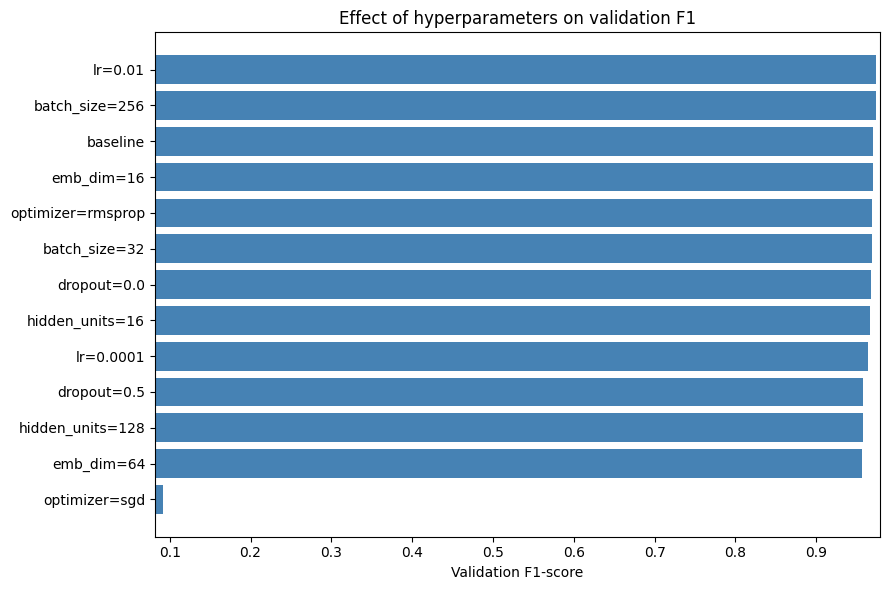

In [8]:
plot_df = res_df.sort_values("val_f1")
plt.figure(figsize=(9, 6))
plt.barh(plot_df["experiment"], plot_df["val_f1"], color="steelblue")
lo = plot_df["val_f1"].min(); plt.xlim(max(0, lo - 0.01), plot_df["val_f1"].max() + 0.005)
plt.xlabel("Validation F1-score"); plt.title("Effect of hyperparameters on validation F1")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/hyperparameter_f1.png", dpi=150); plt.show()

Best configuration (by validation F1): lr=0.01
Confusion matrix [[TN FP],[FN TP]]:
 [[2349   51]
 [  57 2343]]

Accuracy : 0.9775
Precision: 0.9787
Recall   : 0.9762
F1-score : 0.9775

                precision    recall  f1-score   support

Non-clickbait     0.9763    0.9788    0.9775      2400
    Clickbait     0.9787    0.9762    0.9775      2400

     accuracy                         0.9775      4800
    macro avg     0.9775    0.9775    0.9775      4800
 weighted avg     0.9775    0.9775    0.9775      4800



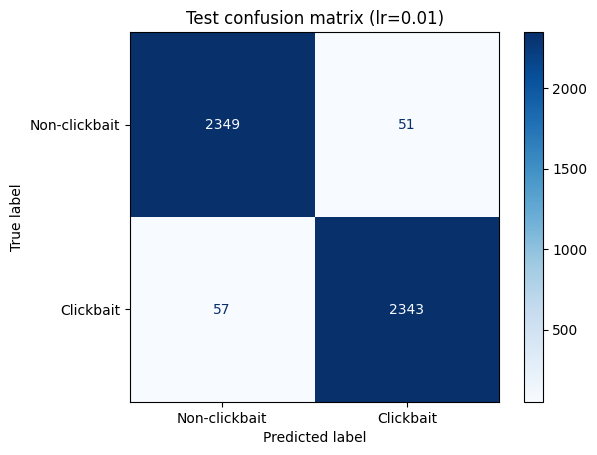

In [9]:
best_name = res_df.loc[0, "experiment"]; best_model = models[best_name]
print("Best configuration (by validation F1):", best_name)

prob = best_model.predict(Xte, verbose=0).ravel(); pred = (prob >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix [[TN FP],[FN TP]]:\n", cm)
print(f"\nAccuracy : {accuracy_score(y_test, pred):.4f}")
print(f"Precision: {precision_score(y_test, pred):.4f}")
print(f"Recall   : {recall_score(y_test, pred):.4f}")
print(f"F1-score : {f1_score(y_test, pred):.4f}")
print("\n", classification_report(y_test, pred, target_names=["Non-clickbait", "Clickbait"], digits=4))

ConfusionMatrixDisplay(cm, display_labels=["Non-clickbait", "Clickbait"]).plot(cmap="Blues", values_format="d")
plt.title(f"Test confusion matrix ({best_name})"); plt.savefig(f"{OUT_DIR}/test_confusion_matrix.png", dpi=150); plt.show()

In [10]:
test_df = pd.DataFrame({"headline": X_test.values, "true": y_test.values, "pred": pred, "prob": prob.round(3)})
pd.set_option("display.max_colwidth", 100)
print("False positives (non-clickbait predicted as clickbait):")
display(test_df[(test_df.true == 0) & (test_df.pred == 1)].sort_values("prob", ascending=False).head(8))
print("False negatives (clickbait predicted as non-clickbait):")
display(test_df[(test_df.true == 1) & (test_df.pred == 0)].sort_values("prob").head(8))

False positives (non-clickbait predicted as clickbait):


,headline,true,pred,prob
988,What Is Facebook Actually Worth?,0,1,1.000
4575,Is This a Shakespeare Which I See Before Me?,0,1,0.999
2292,"Eurovision '09 competitor Chiara talks about her current song ""What If We"" and her past accolades",0,1,0.999
4295,"As Rodriguez Went Pro, His Teammate Went to College",0,1,0.998
497,Making the Sims Into Neighbors You Can Relate To,0,1,0.996
3545,"Zoombak Tracks Your Dog, Your Car, Even Your Children",0,1,0.994
1144,"Looking You Over, With a Shameless Gaze",0,1,0.993
937,"A World of Lingo (Out of This World, Too)",0,1,0.990


False negatives (clickbait predicted as non-clickbait):


,headline,true,pred,prob
133,Adorable Red Panda Cubs Make Public Debut At Chicago Zoo,1,0,0.001
3939,Iraq Just Held Its First Beauty Pageant In More Than 40 Years,1,0,0.002
3139,Storms Have Unveiled A Shipwreck From The 1930s In California,1,0,0.004
558,Top-Ranked Olympic Skier Gus Kenworthy Comes Out As Gay With ESPN Cover,1,0,0.009
1386,Salted Coffee: Is It Less Bitter,1,0,0.013
4602,"Rita Ora Wants To Remake ""Lady Marmalade"" And THAT IS NOT OK",1,0,0.021
2670,17 Rainy Day Outings To Take In London,1,0,0.023
4492,A Best-Selling Author Dismissed Postpartum Depression Screening As A Pharmaceutical Conspiracy,1,0,0.030


In [11]:
best_model.save(f"{OUT_DIR}/best_model.keras")
print("Saved results, figures, and model to", OUT_DIR)

Saved results, figures, and model to outputs
